# Support Vector Machine (RBF)

An SVM looks for the boundary that separates normal from DoS rows with the widest possible margin. With the RBF kernel the boundary can curve: each training row influences nearby points, and how far that influence reaches is set by `gamma`. `C` sets how strongly mistakes on the training rows are punished (large `C` fits the training data tightly, small `C` allows a smoother boundary). Distances matter, so features are standardised first.

Defined in `src/dosdetect/models.py` as `svm()`: `StandardScaler`, then `SVC(C=50, kernel="rbf", gamma="auto", class_weight="balanced")`. `gamma="auto"` means 1 / n_features. `class_weight="balanced"` reweights the classes by how rare they are. Written and tuned by Ethan (PR #5).

In [1]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from dosdetect.data import RESULTS_DIR, prepare_all
from dosdetect.evaluate import evaluate, evaluate_all, metrics_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

Normal and DoS traffic only (`dosdetect.data.prepare_all`). Six setups, three splits at two feature counts:

- **official**: NSL-KDD, train on `KDDTrain+`, test on `KDDTest+`. A share of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm); the count is printed below.
- **holdout**: NSL-KDD, stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **kddcup**: KDDCup'99 (10% file), stratified 80/20 split. The labelled KDDCup test file is no longer downloadable, so there is no official split for this dataset.
- **8 features** (top 8 by |Spearman correlation| with the label, our reading of the paper's filter) or **all 41**. On KDDCup this ranking reproduces the features the paper names (`dst_bytes`, `protocol_type`, the connection counts); on NSL-KDD it does not (see the README). The table below shows the NSL-KDD top 8.

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print(
    "Unseen DoS rows in official test:",
    official["unseen"].sum(),
    "of",
    int(official["y_test"].sum()),
    "DoS rows",
)
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717 of 7458 DoS rows


,|correlation| with label
same_srv_rate,0.8433
flag,0.7974
diff_srv_rate,0.7747
serror_rate,0.7712
srv_serror_rate,0.7686
dst_host_serror_rate,0.7485
dst_host_srv_serror_rate,0.7410
count,0.7366


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only). This cell fits the SVM six times and takes several minutes; the 8-feature fits are the slow ones.

In [3]:
results = evaluate_all(MODELS["svm"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen
"official, 8 features",0.8676,0.9300,0.7517,0.8314,0.8687,0.3605
"official, 41 features",0.9303,0.9921,0.8462,0.9134,0.9895,0.3669
"holdout, 8 features",0.9719,0.9944,0.9360,0.9643,NaN,NaN
"holdout, 41 features",0.9995,0.9995,0.9992,0.9993,NaN,NaN
"kddcup, 8 features",0.9936,0.9997,0.9923,0.9960,NaN,NaN
"kddcup, 41 features",0.9999,1.0000,0.9998,0.9999,NaN,NaN


### Confusion matrices

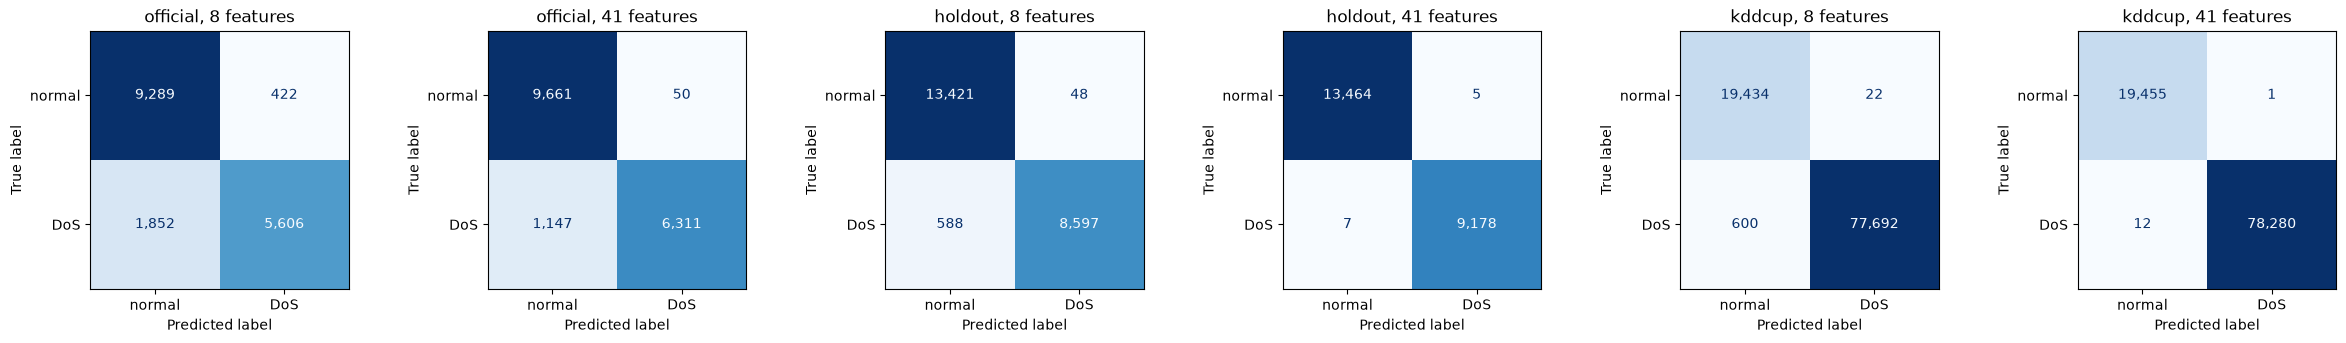

In [4]:
plot_confusions(results);

## Choosing C and gamma

`C=50` and `gamma="auto"` were chosen by the model's author; how is not recorded here. The sweep below is a sanity check, **not a tuning**: it scores on the official test file, so picking the best row would leak the test set into the choice. It uses the official split with all 41 features only, because each 8-feature fit takes one to two minutes. `gamma="scale"` is 1 / (n_features x variance of X); on standardised data that is close to `"auto"`, so the two columns differ little.

In [5]:
full = data[("official", 41)]
rows = []
for gamma in ["auto", "scale"]:
    for c in [1, 10, 30, 50, 100]:
        model = make_pipeline(
            StandardScaler(), SVC(C=c, kernel="rbf", gamma=gamma, class_weight="balanced")
        )
        r = evaluate(model, full)
        rows.append(
            {
                "gamma": gamma,
                "C": c,
                "f1": r["f1"],
                "recall": r["recall"],
                "recall_unseen": r["recall_unseen"],
                "train_time_s": r["train_time_s"],
            }
        )
sweep = pd.DataFrame(rows).set_index(["gamma", "C"])
sweep.round(4)

f1  recall  recall_unseen  train_time_s
gamma C                                               
auto  1    0.8683  0.7734         0.0518        7.7010
      10   0.9056  0.8339         0.3174        3.3689
      30   0.9132  0.8459         0.3745        2.7112
      50   0.9134  0.8462         0.3669        2.3563
      100  0.9143  0.8481         0.3663        2.2404
scale 1    0.8680  0.7731         0.0513        7.7822
      10   0.9058  0.8341         0.3180        3.3576
      30   0.9127  0.8450         0.3704        2.5567
      50   0.9135  0.8465         0.3675        2.3499
      100  0.9143  0.8481         0.3663        2.3659

## Comparison with the other models

Official split, from `results/metrics.csv` (the final full run; nothing is re-fitted here).

In [6]:
metrics = pd.read_csv(RESULTS_DIR / "metrics.csv")
official_all = metrics[metrics["split"] == "official"]
official_all.pivot(index="model", columns="n_features", values=["accuracy", "f1", "recall_unseen"])

accuracy              f1         recall_unseen        
n_features                8       41      8       41            8       41
model                                                                     
decision_tree         0.8497  0.9133  0.8039  0.8928        0.1875  0.3081
knn                   0.8666  0.8953  0.8297  0.8641        0.3192  0.0693
naive_bayes           0.8712  0.6178  0.8371  0.6510        0.4601  0.4426
random_forest         0.8543  0.9012  0.8108  0.8734        0.1986  0.0821
random_forest_tuned   0.8639  0.9059  0.8254  0.8797        0.2994  0.2697
svm                   0.8676  0.9303  0.8314  0.9134        0.3605  0.3669

## Timing and cost

Median of 5 repeats per model (fresh model each time), read from `results/timing.csv`; nothing is re-timed here. The run was on an 8-core machine with other background load, so absolute times depend on the machine; the ratios are within one setup. `train_ratio_vs_decision_tree` is the SVM's median train time divided by the decision tree's in the same setup.

An RBF SVM has to compare training rows with each other (a kernel matrix), so training cost grows faster than linearly with the number of rows. Prediction also compares every test row with every support vector. The 8-feature fits are far slower than the 41-feature ones in the table below, probably because the classes overlap more in 8 dimensions, so more rows become support vectors and the solver needs more iterations (not checked here).

In [7]:
timing = pd.read_csv(RESULTS_DIR / "timing.csv")
print("repeats:", timing["repeats"].iloc[0], " cpu_count:", timing["cpu_count"].iloc[0])
svm_timing = timing[timing["model"] == "svm"].set_index(["split", "n_features"])[
    [
        "train_s_median",
        "predict_s_median",
        "train_ratio_vs_decision_tree",
        "predict_ratio_vs_naive_bayes",
    ]
]
svm_timing.round(4)

repeats: 5  cpu_count: 8


train_s_median  predict_s_median  \
split    n_features                                     
official 8                  90.5265            2.5807   
         41                  2.0192            0.2293   
holdout  8                 137.3462            2.6614   
         41                  1.1917            0.2592   
kddcup   8                  37.0748            7.5466   
         41                 22.4176            1.9551   

                     train_ratio_vs_decision_tree  \
split    n_features                                 
official 8                              1313.4226   
         41                                5.3126   
holdout  8                              2957.7085   
         41                                4.0375   
kddcup   8                               244.2297   
         41                               36.9712   

                     predict_ratio_vs_naive_bayes  
split    n_features                                
official 8                              2731.4865  
         41                               98.2504  
holdout  8                              2437.6928  
         41                              105.4383  
kddcup   8                              2406.9511  
         41                              145.0405

## Leave-one-attack-out

The official split has only a few unseen attack types, so it is one test of the claim that new attacks are missed. This section repeats it more broadly, from `results/attack_out.csv` (made by `python -m dosdetect.attack_out`, not re-run here). For each dataset (NSL-KDD `KDDTrain+` only, and KDDCup'99 10%) and each held-out group (neptune; smurf; back+land; teardrop+pod), the model is trained without any row of that group, on an 80% split of the rest, plus a fresh feature selection on that training set. It is tested on the other 20% plus the held-out rows (capped at 20,000). **One seed (42), so differences of a few points are within noise.**

- `recall_heldout`: share of the held-out attack rows flagged as DoS.
- `recall_seen`: recall on the DoS types it did train on.
- `false_alarm_rate`: share of normal test rows flagged as DoS.

In [8]:
attack_out = pd.read_csv(RESULTS_DIR / "attack_out.csv")
loao = attack_out[attack_out["model"] == "svm"].set_index(["dataset", "n_features", "group"])
loao_cols = ["n_heldout", "recall_heldout", "recall_seen", "false_alarm_rate"]
loao[loao_cols]

n_heldout  recall_heldout  recall_seen  \
dataset n_features group                                                  
nsl-kdd 8          neptune           20000          0.0001       0.9894   
        41         neptune           20000          0.0000       0.9968   
        8          smurf              2646          0.0000       0.9774   
        41         smurf              2646          0.0000       1.0000   
        8          back+land           974          0.0164       0.9594   
        41         back+land           974          0.0000       0.9994   
        8          teardrop+pod       1093          0.0000       0.9605   
        41         teardrop+pod       1093          0.0302       0.9994   
kddcup  8          neptune           20000          0.6935       0.9919   
        41         neptune           20000          0.0000       0.9999   
        8          smurf             20000          0.0000       0.9899   
        41         smurf             20000          0.0000       1.0000   
        8          back+land          2224          0.0000       0.9968   
        41         back+land          2224          0.0000       0.9999   
        8          teardrop+pod       1243          0.0805       0.9938   
        41         teardrop+pod       1243          0.0000       0.9999   

                                 false_alarm_rate  
dataset n_features group                           
nsl-kdd 8          neptune                 0.0053  
        41         neptune                 0.0009  
        8          smurf                   0.0026  
        41         smurf                   0.0005  
        8          back+land               0.0033  
        41         back+land               0.0004  
        8          teardrop+pod            0.0037  
        41         teardrop+pod            0.0004  
kddcup  8          neptune                 0.0002  
        41         neptune                 0.0001  
        8          smurf                   0.0002  
        41         smurf                   0.0001  
        8          back+land               0.0003  
        41         back+land               0.0001  
        8          teardrop+pod            0.0003  
        41         teardrop+pod            0.0002

Mean over the four groups for each dataset and feature count (a mean can hide a single group doing very differently; read the per-group table above first):

In [9]:
loao_mean = loao.groupby(level=["dataset", "n_features"])[
    ["recall_heldout", "recall_seen", "false_alarm_rate"]
].mean()
loao_mean.round(4)

recall_heldout  recall_seen  false_alarm_rate
dataset n_features                                               
kddcup  8                   0.1935       0.9931            0.0002
        41                  0.0000       0.9999            0.0001
nsl-kdd 8                   0.0041       0.9717            0.0037
        41                  0.0076       0.9989            0.0006

In [10]:
print("rows with recall_heldout < 0.2:", int((loao["recall_heldout"] < 0.2).sum()), "of", len(loao))
print(
    "min recall_seen:",
    loao["recall_seen"].min(),
    " max false_alarm_rate:",
    loao["false_alarm_rate"].max(),
)
loao[loao["recall_heldout"] >= 0.2][loao_cols]

rows with recall_heldout < 0.2: 15 of 16
min recall_seen: 0.9594  max false_alarm_rate: 0.0053


,,,n_heldout,recall_heldout,recall_seen,false_alarm_rate
dataset,n_features,group,,,,
kddcup,8,neptune,20000,0.6935,0.9919,0.0002


## Takeaways

- **Best of the six models on the official file with all 41 features, middling with 8.** At 41 features the SVM reaches 93.0% accuracy and F1 0.9134 on official, the highest accuracy in the comparison table (decision tree 91.3%, KNN 89.5%). At 8 features it is 86.8% accuracy and F1 0.8314, level with KNN (86.7%) and just under Naive Bayes (87.1%). On holdout and kddcup it is near-perfect: 99.95% and 99.99% accuracy at 41 features, 97.2% and 99.4% at 8.
- **Unseen attacks are still the weak spot.** `recall_unseen` is 36.1% with 8 features and 36.7% with 41, against `recall_seen` of 86.9% and 99.0%. That is better than the decision tree (18.8% and 30.8%) and the default forest, but Naive Bayes is higher at both feature counts (46.0% and 44.3%).
- **C=50 is a reasonable setting but the sweep does not single it out.** On official at 41 features, C=1 is clearly worse (F1 0.8683, recall_unseen 0.0518) and C=10 is behind (0.9056); from C=30 on F1 is 0.9132 to 0.9143, and C=100 scores marginally above C=50 (0.9143 against 0.9134). These differences are far smaller than the gap to C=1, and the sweep scores on the test file, so it is not a tuning. `gamma="scale"` and `"auto"` give almost the same numbers.
- **Very expensive to train and predict with 8 features.** The median train time is 90.5 s on official, 137.3 s on holdout and 37.1 s on kddcup at 8 features, which is 1313x, 2958x and 244x the decision tree's. With 41 features it is 2.0 s, 1.2 s and 22.4 s (4.0x to 37.0x the tree). Median predict time is 2.58 s at 8 features on official, 2407x to 2731x Naive Bayes' at 8 features and 98x to 145x at 41. Medians of 5 runs on an 8-core machine with other background load.
- **Leave-one-attack-out confirms the unseen-attack weakness, with one exception.** (One seed.) 15 of the 16 dataset/feature/group rows have `recall_heldout` below 0.2, while `recall_seen` stays at 95.9% or more and false alarms at 0.53% or less of normal rows. The exception is KDDCup with neptune held out at 8 features (0.6935); at 41 features the same group gets 0.0000, so this looks like a feature-set accident of one seed. Group means range from 0.0000 to 0.1935 (the highest, kddcup at 8 features, is pulled up by that row). The official-split result above (36.1% and 36.7% unseen recall) is better than these held-out groups suggest, so it should not be read as a general ability to detect new attack types.
